# Chart makeovers – before and after

**Video 8.1** · ShopKart project

**Goal:** Create the 'bad chart vs good chart' images used on the Video 8.1 slides: a truncated axis, a 3D-style pie, and a cluttered chart – each with its fixed version.

**How to open in Colab:** go to colab.research.google.com → File → Upload notebook → choose this file. Then click the folder icon on the left and drag these data files in: `shopkart_clean.csv`. Then run cells from top to bottom (Shift + Enter).

This notebook is mainly for the course creator. Learners can run it too: it shows that a bad chart and a good chart can come from the SAME numbers.

In [1]:
# Import the libraries we need
import os
import pandas as pd
import matplotlib.pyplot as plt

# Load the clean ShopKart data we created in Module 6
df = pd.read_csv("shopkart_clean.csv")

# A folder to save our chart images into
os.makedirs("images", exist_ok=True)

print(df.shape)
df.head(3)

(5000, 21)


,order_id,order_date,customer_id,product_id,quantity,unit_price,discount,city,payment_mode,delivery_days,...,returned,product_name,category,cost_price,gender,age,membership,revenue,profit,order_month
0,O10001,2025-01-01,C0593,P048,6,362,0.20,Delhi,COD,4,...,N,Wings of Fire,Books,240,Female,26,Prime,1737.6,297.6,1
1,O10002,2025-01-01,C0367,P049,2,300,0.05,Chennai,Debit Card,4,...,N,Face Wash,Beauty,150,Male,35,Free,570.0,270.0,1
2,O10003,2025-01-01,C0707,P020,1,2258,0.05,Delhi,Debit Card,2,...,N,Saree,Fashion,1280,Male,41,Prime,2145.1,865.1,1


In [2]:
# Our course colours: one main colour, one highlight colour, one grey
MAIN = "#2a78d6"       # blue  - normal bars and lines
HIGHLIGHT = "#eb6834"  # orange - the one thing we want people to notice
GREY = "#b8b6ae"       # grey  - everything else

## Makeover 1 – the truncated axis

Delhi and Bengaluru have almost the same revenue. If the y-axis starts at ₹22 lakh instead of 0, Delhi looks about 3 times bigger. Same data, misleading picture.

In [3]:
# Revenue of the top 2 cities, in lakh rupees (1 lakh = 1,00,000)
top2 = df.groupby("city")["revenue"].sum().sort_values(ascending=False).head(2) / 100000
print(top2.round(2))
print("Delhi is", round((top2.iloc[0] / top2.iloc[1] - 1) * 100, 1), "% higher than Bengaluru")

city
Delhi        23.23
Bengaluru    22.57
Name: revenue, dtype: float64
Delhi is 3.0 % higher than Bengaluru


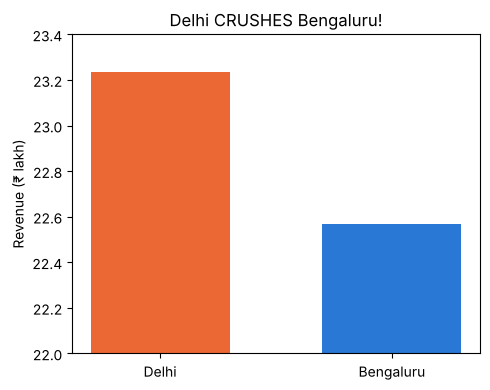

In [4]:
# BEFORE: y-axis starts at 22 lakh -> the gap looks huge
fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(top2.index, top2.values, color=[HIGHLIGHT, MAIN], width=0.6)
ax.set_ylim(22, 23.4)
ax.set_title("Delhi CRUSHES Bengaluru!")
ax.set_ylabel("Revenue (₹ lakh)")
plt.tight_layout()
plt.savefig("images/M08_makeover1_truncated_BEFORE.png", dpi=150)
plt.show()

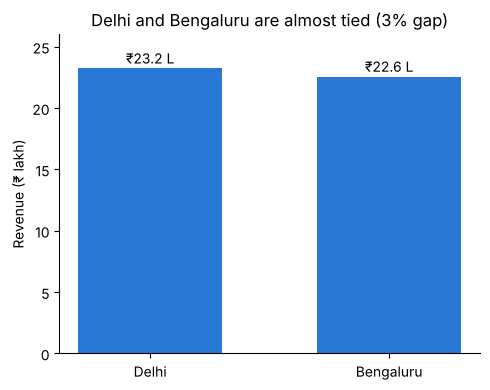

In [5]:
# AFTER: y-axis starts at 0 -> honest picture, plus a message title
fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(top2.index, top2.values, color=MAIN, width=0.6)
ax.set_ylim(0, 26)
for i, v in enumerate(top2.values):
    ax.text(i, v + 0.4, f"₹{v:.1f} L", ha="center")
ax.set_title("Delhi and Bengaluru are almost tied (3% gap)")
ax.set_ylabel("Revenue (₹ lakh)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("images/M08_makeover1_truncated_AFTER.png", dpi=150)
plt.show()

## Makeover 2 – the 3D pie

Pies with many slices, shadows and a tilted 3D look make it impossible to compare slices. Front slices look bigger than they are. A sorted bar chart fixes it.

In [6]:
# Revenue share by city (10 cities)
city_rev = df.groupby("city")["revenue"].sum().sort_values(ascending=False)
share = (city_rev / city_rev.sum() * 100).round(1)
share

city
Delhi        15.8
Bengaluru    15.3
Mumbai       14.2
Hyderabad    10.2
Pune          9.4
Chennai       9.1
Kolkata       8.4
Ahmedabad     7.2
Lucknow       5.4
Jaipur        4.9
Name: revenue, dtype: float64

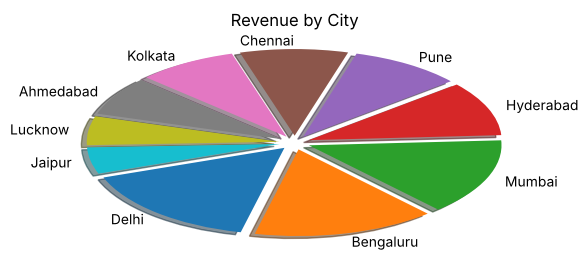

In [7]:
# BEFORE: a tilted, exploded, shadowed pie with 10 slices
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.pie(city_rev.values, labels=city_rev.index, shadow=True,
       explode=[0.08] * len(city_rev), startangle=200,
       colors=plt.cm.tab10.colors)
ax.set_aspect(0.45)          # squash the circle so it looks "3D" - this distorts the slices
ax.set_title("Revenue by City")
plt.tight_layout()
plt.savefig("images/M08_makeover2_3Dpie_BEFORE.png", dpi=150)
plt.show()

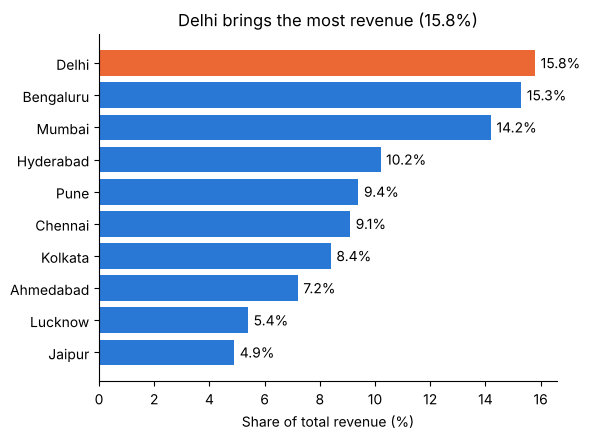

In [8]:
# AFTER: sorted horizontal bar chart, one colour, highlight the leader
fig, ax = plt.subplots(figsize=(6, 4.5))
s = share.sort_values()                       # smallest at bottom, biggest on top
bar_colors = [HIGHLIGHT if c == "Delhi" else MAIN for c in s.index]
ax.barh(s.index, s.values, color=bar_colors)
for i, v in enumerate(s.values):
    ax.text(v + 0.2, i, f"{v}%", va="center")
ax.set_xlabel("Share of total revenue (%)")
ax.set_title("Delhi brings the most revenue (15.8%)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("images/M08_makeover2_3Dpie_AFTER.png", dpi=150)
plt.show()

## Makeover 3 – clutter vs focus

Ten colours and no message vs grey bars with ONE highlighted bar and a title that says the finding.

In [9]:
ret_city = (df["returned"].eq("Y").groupby(df["city"]).mean() * 100).sort_values(ascending=False)
overall = df["returned"].eq("Y").mean() * 100
print(ret_city.round(1))
print("Overall return rate:", round(overall, 1), "%")
print("Pune vs overall:", round(ret_city["Pune"] / overall, 1), "x")

city
Pune         32.4
Kolkata      14.3
Ahmedabad    14.2
Lucknow      13.5
Jaipur       13.3
Hyderabad    12.7
Chennai      12.7
Bengaluru    12.1
Delhi        10.2
Mumbai        9.1
Name: returned, dtype: float64
Overall return rate: 13.7 %
Pune vs overall: 2.4 x


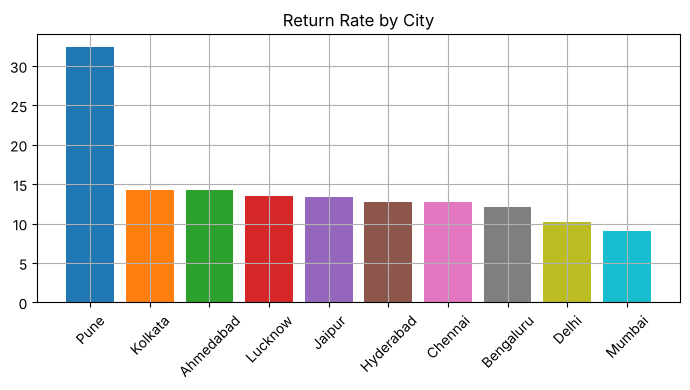

In [10]:
# BEFORE: rainbow colours, gridlines, no message
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(ret_city.index, ret_city.values, color=plt.cm.tab10.colors)
ax.grid(True)
ax.set_title("Return Rate by City")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("images/M08_makeover3_clutter_BEFORE.png", dpi=150)
plt.show()

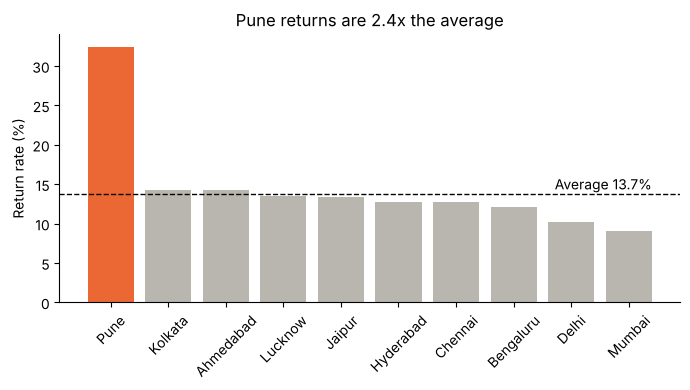

In [11]:
# AFTER: grey bars, Pune highlighted, average line, message title
fig, ax = plt.subplots(figsize=(7, 4))
colors = [HIGHLIGHT if c == "Pune" else GREY for c in ret_city.index]
ax.bar(ret_city.index, ret_city.values, color=colors)
ax.axhline(overall, color="black", linestyle="--", linewidth=1)
ax.text(9.4, overall + 0.6, f"Average {overall:.1f}%", ha="right")
ratio = ret_city["Pune"] / overall
ax.set_title(f"Pune returns are {ratio:.1f}x the average")
ax.set_ylabel("Return rate (%)")
ax.spines[["top", "right"]].set_visible(False)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("images/M08_makeover3_clutter_AFTER.png", dpi=150)
plt.show()

All six images are now in the `images/` folder. In Colab, open the folder panel, right-click a file → Download, and paste it onto your slides.